In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df = pd.read_csv("Data/raw_data/train.csv")

In [3]:
train_df.shape

(3000888, 6)

In [4]:
train_df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [6]:
train_df.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [7]:
train_df.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='object')

In [8]:
train_df.dtypes

id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

In [9]:
train_df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [10]:
# unique() : list all unique values in a column
# nunique() : counts how many distinct values exist
print("Number of unique stores:", train_df["store_nbr"].nunique())
print("Number of product families:", train_df["family"].nunique())
print("Product families:")
print(train_df["family"].unique())

Number of unique stores: 54
Number of product families: 33
Product families:
['AUTOMOTIVE' 'BABY CARE' 'BEAUTY' 'BEVERAGES' 'BOOKS' 'BREAD/BAKERY'
 'CELEBRATION' 'CLEANING' 'DAIRY' 'DELI' 'EGGS' 'FROZEN FOODS' 'GROCERY I'
 'GROCERY II' 'HARDWARE' 'HOME AND KITCHEN I' 'HOME AND KITCHEN II'
 'HOME APPLIANCES' 'HOME CARE' 'LADIESWEAR' 'LAWN AND GARDEN' 'LINGERIE'
 'LIQUOR,WINE,BEER' 'MAGAZINES' 'MEATS' 'PERSONAL CARE' 'PET SUPPLIES'
 'PLAYERS AND ELECTRONICS' 'POULTRY' 'PREPARED FOODS' 'PRODUCE'
 'SCHOOL AND OFFICE SUPPLIES' 'SEAFOOD']


In [11]:
# dates are usually imported as object or string datatype, so we need to conert them to datetime (actual calendar dates)
train_df["date"] = pd.to_datetime(train_df["date"])
print("Start date:", train_df["date"].min())
print("End date:", train_df["date"].max())

Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00


In [12]:
print(train_df['date'].dtypes)

datetime64[ns]


In [13]:
train_df.duplicated().sum()

np.int64(0)

In [14]:
# checking whether each store has all the product families
# groupby() : splits dataset into separate groups basd on shared values in a column so that we cn perform calculations in each group individually
# 
store_family_count = train_df.groupby("store_nbr")["family"].nunique()
print(store_family_count)

store_nbr
1     33
2     33
3     33
4     33
5     33
6     33
7     33
8     33
9     33
10    33
11    33
12    33
13    33
14    33
15    33
16    33
17    33
18    33
19    33
20    33
21    33
22    33
23    33
24    33
25    33
26    33
27    33
28    33
29    33
30    33
31    33
32    33
33    33
34    33
35    33
36    33
37    33
38    33
39    33
40    33
41    33
42    33
43    33
44    33
45    33
46    33
47    33
48    33
49    33
50    33
51    33
52    33
53    33
54    33
Name: family, dtype: int64


In [15]:
train_df["sales"].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

In [16]:
zero_sales = (train_df['sales'] == 0).sum()
print('Zero sales records :',zero_sales)

Zero sales records : 939130


In [17]:
# finding the highest sellling product family
family_sales = (train_df.groupby('family')['sales'].sum().sort_values(ascending = False))
family_sales.head(10)

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

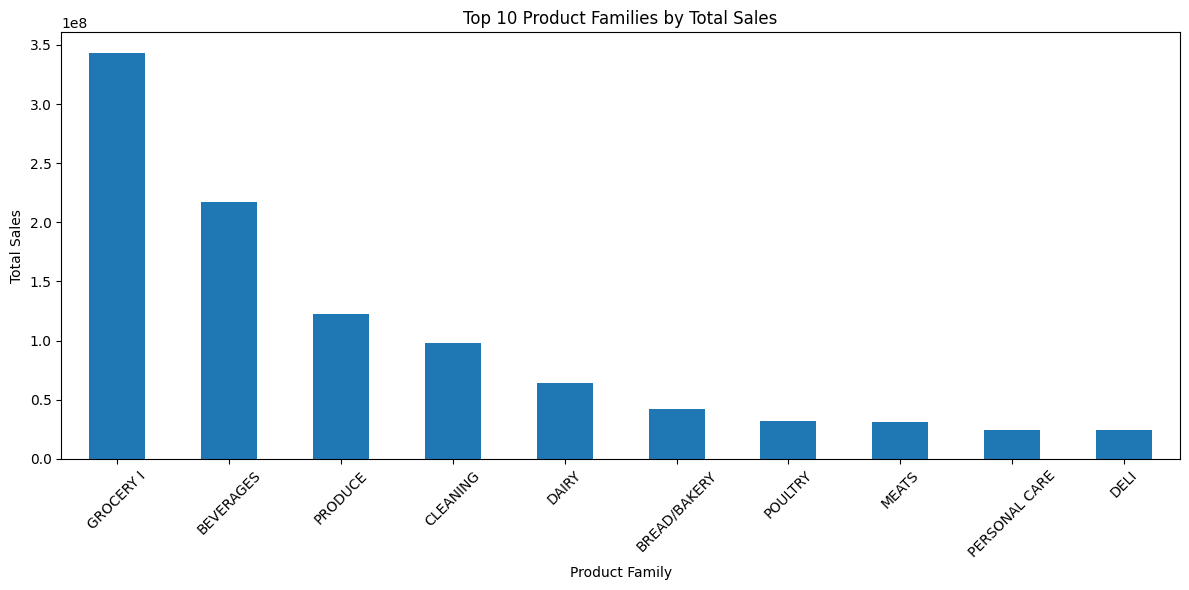

In [18]:
plt.figure(figsize=(12, 6))
family_sales.head(10).plot(kind = 'bar')
plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Product Family")
plt.ylabel('Total Sales')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [19]:
# compare sales across stores
store_sales = (train_df.groupby('store_nbr')['sales'].sum().sort_values(ascending = False))
store_sales.head(10)

store_nbr
44    6.208755e+07
45    5.449801e+07
47    5.094831e+07
3     5.048191e+07
49    4.342010e+07
46    4.189606e+07
48    3.593313e+07
51    3.291149e+07
8     3.049429e+07
50    2.865302e+07
Name: sales, dtype: float64

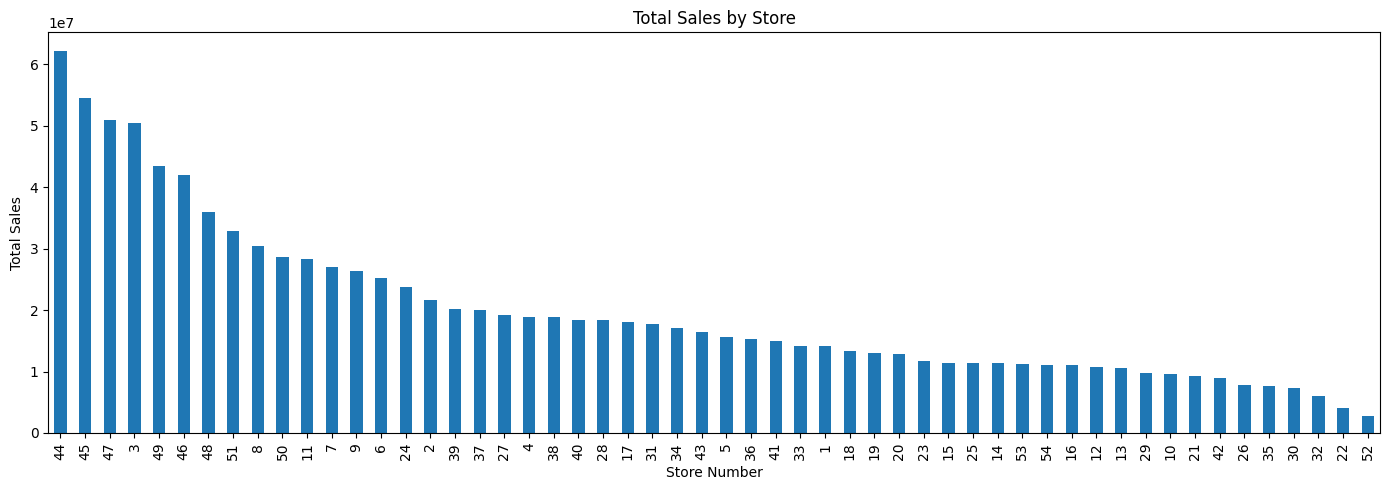

In [20]:
plt.figure(figsize = (14,5))
store_sales.plot(kind = 'bar')
plt.title('Total Sales by Store')
plt.xlabel('Store Number')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

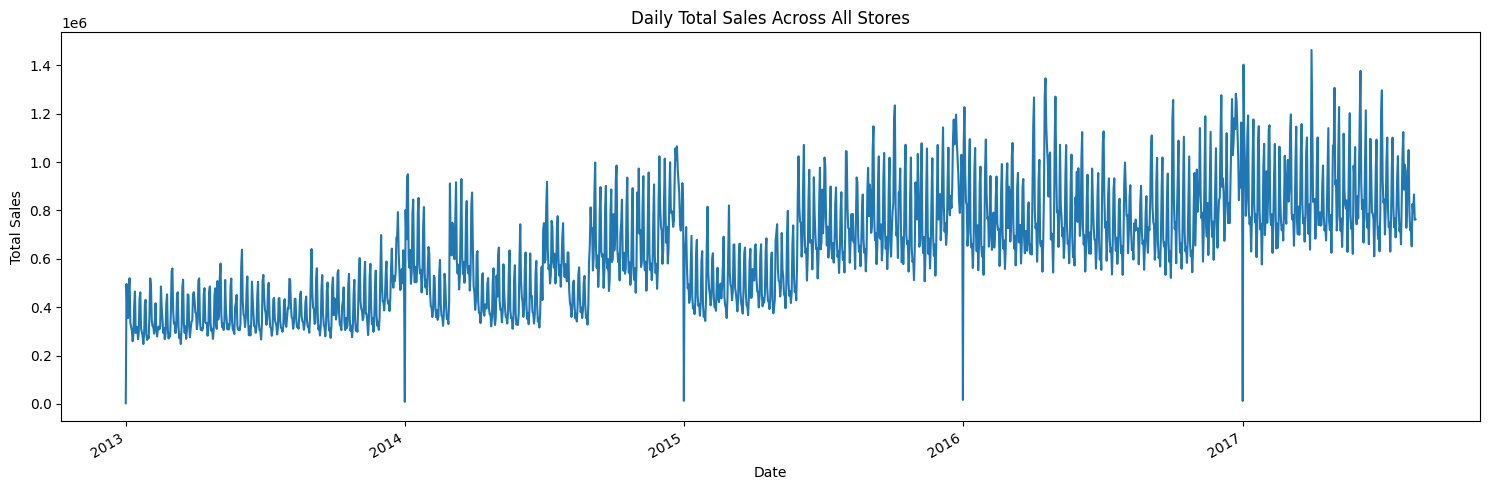

In [21]:
# daily sales trends 
daily_sales = train_df.groupby("date")["sales"].sum()
plt.figure(figsize=(15, 5))
daily_sales.plot()
plt.title("Daily Total Sales Across All Stores")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [22]:
# promotional activity
train_df['onpromotion'].describe()

count    3.000888e+06
mean     2.602770e+00
std      1.221888e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      7.410000e+02
Name: onpromotion, dtype: float64

In [23]:
# checking how many records have zero promotional activity
print("Records with no promotions : ", (train_df['onpromotion'] == 0).sum())
print('Records with promotions : ', (train_df['onpromotion']>0).sum())

Records with no promotions :  2389559
Records with promotions :  611329


In [24]:
# compare the sales with promotional activity
promotional_analysis = (train_df.groupby('onpromotion')['sales'].mean())
promotional_analysis.head(10)

onpromotion
0     158.246681
1     467.556532
2     662.925632
3     871.408092
4     969.916135
5    1010.659835
6    1022.854287
7    1022.567058
8    1174.757003
9    1258.733993
Name: sales, dtype: float64

date
2013-01    1.032762e+07
2013-02    9.658960e+06
2013-03    1.142850e+07
2013-04    1.099346e+07
2013-05    1.159770e+07
2013-06    1.168934e+07
2013-07    1.125740e+07
2013-08    1.173779e+07
2013-09    1.179293e+07
2013-10    1.177562e+07
Freq: M, Name: sales, dtype: float64


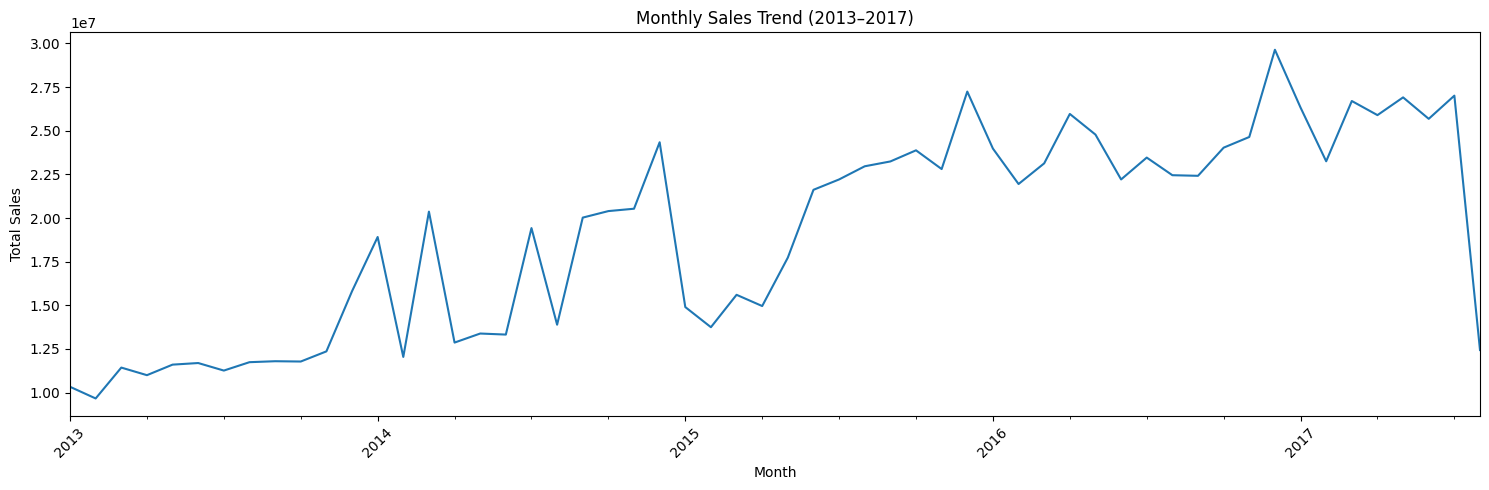

In [25]:
# analyze monthly sales trends 
monthly_sales = train_df.groupby(
    train_df["date"].dt.to_period("M")
)["sales"].sum()
print(monthly_sales.head(10))
plt.figure(figsize=(15, 5))
monthly_sales.plot()
plt.title("Monthly Sales Trend (2013–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
# analyze sales by day of the week
train_df["day_of_week"] = train_df["date"].dt.day_name()

weekday_sales = (
    train_df.groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

weekday_sales

day_of_week
Monday       346.544732
Tuesday      319.823843
Wednesday    332.909401
Thursday     283.540517
Friday       325.238138
Saturday     433.336472
Sunday       463.085366
Name: sales, dtype: float64

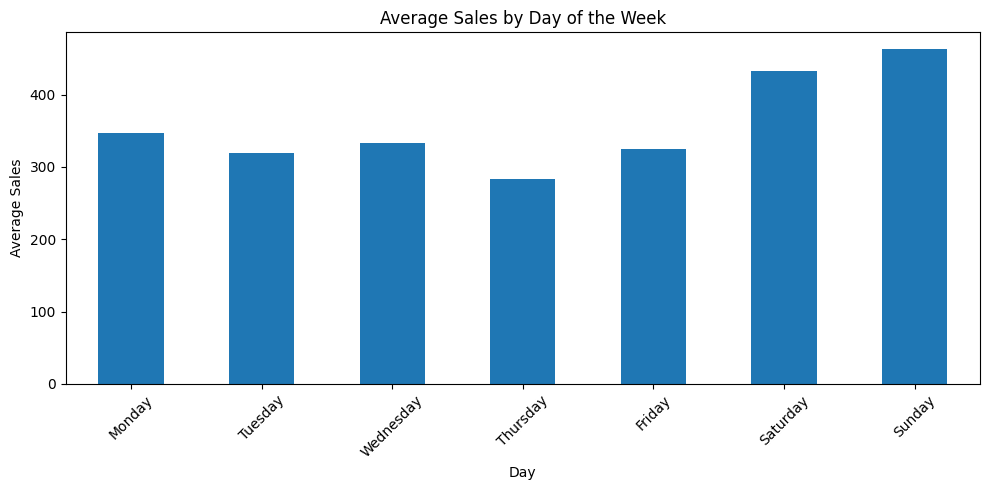

In [27]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
# analyze sales by year
yearly_sales = train_df.groupby(
    train_df["date"].dt.year
)["sales"].sum()

yearly_sales

date
2013    1.404190e+08
2014    2.094742e+08
2015    2.408801e+08
2016    2.886545e+08
2017    1.942171e+08
Name: sales, dtype: float64

## Initial EDA Findings

1. The dataset contains 3,000,888 records and 6 columns.
2. It covers 54 stores and 33 product families.
3. No missing values or duplicate records were found.
4. Approximately 31.29% of records have zero sales.
5. GROCERY I has the highest total sales among product families.
6. Store 44 has the highest total sales among the stores.
7. The overall daily sales graph shows an increasing trend
   between 2013 and 2017.
8. Sales distribution is highly right-skewed, indicating
   considerable variation in sales values.

## Additional EDA Findings

1. Approximately 20.37% of the records contain promotional activity, while 79.63% have no promotions.
2. Average sales generally increase with the number of promoted items, suggesting an association between promotions and sales.
3. Sales fluctuate across months, indicating possible seasonal variations.
4. Sunday has the highest average sales (463.09), while Thursday has the lowest (283.54).
5. Saturday and Sunday show higher average sales compared with weekdays.
6. Annual sales increased from 2013 to 2016. The 2017 total is lower because the dataset covers only January to August 15.
7. These patterns suggest that promotional activity, calendar effects, and store-level differences may be useful features for demand prediction.

In [29]:
import os

files = os.listdir("Data/raw_data")

for file in files:
    print(file)

holidays_events.csv
oil.csv
sample_submission.csv
stores.csv
test.csv
train.csv
transactions.csv


In [30]:
# Load the supporting datasets

stores_df = pd.read_csv("Data/raw_data/stores.csv")
oil_df = pd.read_csv("Data/raw_data/oil.csv")
holidays_df = pd.read_csv("Data/raw_data/holidays_events.csv")
transactions_df = pd.read_csv("Data/raw_data/transactions.csv")
test_df = pd.read_csv("Data/raw_data/test.csv")

# Display dataset shapes

print("Stores:", stores_df.shape)
print("Oil:", oil_df.shape)
print("Holidays:", holidays_df.shape)
print("Transactions:", transactions_df.shape)
print("Test:", test_df.shape)

Stores: (54, 5)
Oil: (1218, 2)
Holidays: (350, 6)
Transactions: (83488, 3)
Test: (28512, 5)


In [38]:
print(stores_df.columns)
stores_df.head()

Index(['store_nbr', 'city', 'state', 'type', 'cluster'], dtype='object')


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [37]:
print(oil_df.columns)
oil_df.head()

Index(['date', 'dcoilwtico'], dtype='object')


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [40]:
print(holidays_df.columns)
holidays_df.head()

Index(['date', 'type', 'locale', 'locale_name', 'description', 'transferred'], dtype='object')


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [41]:
print(transactions_df.columns)
transactions_df.head()

Index(['date', 'store_nbr', 'transactions'], dtype='object')


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [42]:
print(test_df.columns)
test_df.head()

Index(['id', 'date', 'store_nbr', 'family', 'onpromotion'], dtype='object')


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [44]:
# Display the columns and first 5 rows

datasets = {
    "Stores": stores_df,
    "Oil": oil_df,
    "Holidays": holidays_df,
    "Transactions": transactions_df,
    "Test": test_df
}

for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print("Columns:", df.columns.tolist())
    display(df.head())


Stores
Columns: ['store_nbr', 'city', 'state', 'type', 'cluster']


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4



Oil
Columns: ['date', 'dcoilwtico']


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20



Holidays
Columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False



Transactions
Columns: ['date', 'store_nbr', 'transactions']


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922



Test
Columns: ['id', 'date', 'store_nbr', 'family', 'onpromotion']


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [52]:
# merge train.csv with stores.csv
data = train_df.merge(stores_df, on = "store_nbr")

In [55]:
data.shape

(3000888, 11)

In [56]:
data.head()

,id,date,store_nbr,family,sales,onpromotion,day_of_week,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Tuesday,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,Tuesday,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,Tuesday,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,Tuesday,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,Tuesday,Quito,Pichincha,D,13


In [57]:
data.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
day_of_week    0
city           0
state          0
type           0
cluster        0
dtype: int64

In [58]:
data.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion',
       'day_of_week', 'city', 'state', 'type', 'cluster'],
      dtype='object')

In [62]:
# create time based features
# Extract date-based features

data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_year"] = data["date"].dt.dayofyear
data["week_of_year"] = data["date"].dt.isocalendar().week.astype(int)

# Weekend indicator
data["is_weekend"] = (
    data["date"].dt.dayofweek >= 5
).astype(int)

# Display the result
display(data.head())

,id,date,store_nbr,family,sales,onpromotion,day_of_week,city,state,type,cluster,year,month,day,day_of_year,week_of_year,is_weekend
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Tuesday,Quito,Pichincha,D,13,2013,1,1,1,1,0
1,1,2013-01-01,1,BABY CARE,0.0,0,Tuesday,Quito,Pichincha,D,13,2013,1,1,1,1,0
2,2,2013-01-01,1,BEAUTY,0.0,0,Tuesday,Quito,Pichincha,D,13,2013,1,1,1,1,0
3,3,2013-01-01,1,BEVERAGES,0.0,0,Tuesday,Quito,Pichincha,D,13,2013,1,1,1,1,0
4,4,2013-01-01,1,BOOKS,0.0,0,Tuesday,Quito,Pichincha,D,13,2013,1,1,1,1,0


In [64]:
# create lag features
# Sort data chronologically

data = data.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# Create lag features separately for each store and family

grouped = data.groupby(
    ["store_nbr", "family"]
)["sales"]

data["lag_1"] = grouped.shift(1)
data["lag_7"] = grouped.shift(7)
data["lag_14"] = grouped.shift(14)

# Check the result
display(
    data[
        ["date", "store_nbr", "family", "sales",
         "lag_1", "lag_7", "lag_14"]
    ].head(20)
)

,date,store_nbr,family,sales,lag_1,lag_7,lag_14
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0.0,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,2.0,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,3.0,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,3.0,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.0,5.0,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.0,2.0,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.0,0.0,0.0,NaN
8,2013-01-09,1,AUTOMOTIVE,2.0,2.0,2.0,NaN
9,2013-01-10,1,AUTOMOTIVE,2.0,2.0,3.0,NaN


This is an important step in time-series forecasting.

Lag features allow the model to learn from previous sales for the same store and product family.

We'll create:
- lag_1: Sales from the previous day.
- lag_7: Sales from 7 days ago.
- lag_14: Sales from 14 days ago.

Grouping by both store_nbr and family ensures that sales from one store or product family never become lag values for another.

In [65]:
# check missing values created by lag features
print(data[["lag_1", "lag_7", "lag_14"]].isnull().sum())

lag_1      1782
lag_7     12474
lag_14    24948
dtype: int64


Feature	Missing values	Reason

lag_1	1,782	First day of each store-family series

lag_7	12,474	First 7 days of each series

lag_14	24,948	First 14 days of each series

In [66]:
# create rolling average features 
# Create rolling average features

data["rolling_mean_7"] = (
    data.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

data["rolling_mean_14"] = (
    data.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=14).mean())
)

# Check the results

display(
    data[
        ["date", "store_nbr", "family", "sales",
         "rolling_mean_7", "rolling_mean_14"]
    ].head(20)
)

,date,store_nbr,family,sales,rolling_mean_7,rolling_mean_14
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.0,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.0,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.0,2.142857,NaN
8,2013-01-09,1,AUTOMOTIVE,2.0,2.428571,NaN
9,2013-01-10,1,AUTOMOTIVE,2.0,2.428571,NaN


Rolling averages help the model understand recent sales patterns.

We'll create:
- rolling_mean_7: Average sales over the previous 7 days.
- rolling_mean_14: Average sales over the previous 14 days.
Important: We use shift(1) before calculating the rolling average. This prevents the current day's sales from leaking into its own prediction.

In [67]:
# check missing values 
print(
    data[
        ["lag_1", "lag_7", "lag_14",
         "rolling_mean_7", "rolling_mean_14"]
    ].isnull().sum()
)

lag_1               1782
lag_7              12474
lag_14             24948
rolling_mean_7     12474
rolling_mean_14    24948
dtype: int64


In [68]:
# remove rows with missing lag features
# Remove rows with missing lag and rolling features

model_data = data.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_14",
        "rolling_mean_7",
        "rolling_mean_14"
    ]
).copy()

print("Original dataset shape:", data.shape)
print("Model dataset shape:", model_data.shape)

print("\nMissing values in model dataset:")
print(model_data.isnull().sum())

Original dataset shape: (3000888, 22)
Model dataset shape: (2975940, 22)

Missing values in model dataset:
id                 0
date               0
store_nbr          0
family             0
sales              0
onpromotion        0
day_of_week        0
city               0
state              0
type               0
cluster            0
year               0
month              0
day                0
day_of_year        0
week_of_year       0
is_weekend         0
lag_1              0
lag_7              0
lag_14             0
rolling_mean_7     0
rolling_mean_14    0
dtype: int64


In [69]:
# check the date range
print("Start date:", model_data["date"].min())
print("End date:", model_data["date"].max())

print("\nNumber of stores:",
      model_data["store_nbr"].nunique())

print("Number of product families:",
      model_data["family"].nunique())

Start date: 2013-01-15 00:00:00
End date: 2017-08-15 00:00:00

Number of stores: 54
Number of product families: 33


In [70]:
# prepare chronological training and validation sets
# Define validation period

validation_start = pd.Timestamp("2017-07-17")

train_data = model_data[
    model_data["date"] < validation_start
].copy()

validation_data = model_data[
    model_data["date"] >= validation_start
].copy()

print("Training shape:", train_data.shape)
print("Validation shape:", validation_data.shape)

print("\nTraining dates:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation dates:")
print(validation_data["date"].min(), "to", validation_data["date"].max())

Training shape: (2922480, 22)
Validation shape: (53460, 22)

Training dates:
2013-01-15 00:00:00 to 2017-07-16 00:00:00

Validation dates:
2017-07-17 00:00:00 to 2017-08-15 00:00:00


In real forecasting, we predict future sales using past information. A random split could mix future and past records, making our evaluation unreliable.

# build a baseline model

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual sales
y_true = validation_data["sales"]

# Baseline predictions using sales from 7 days ago
y_baseline = validation_data["lag_7"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(y_true, y_baseline)

baseline_rmse = np.sqrt(
    mean_squared_error(y_true, y_baseline)
)

print("Baseline Model Results")
print("----------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

Baseline Model Results
----------------------
MAE: 85.02
RMSE: 310.95


# random forest model

In [72]:
#  Encode categorical features
# Categorical columns
categorical_cols = [
    "store_nbr",
    "family",
    "day_of_week",
    "city",
    "state",
    "type",
    "cluster"
]

# Convert categories into numerical codes
for col in categorical_cols:
    model_data[col] = model_data[col].astype("category").cat.codes

# Recreate training and validation datasets
train_data = model_data[
    model_data["date"] < validation_start
].copy()

validation_data = model_data[
    model_data["date"] >= validation_start
].copy()

print("Training shape:", train_data.shape)
print("Validation shape:", validation_data.shape)

Training shape: (2922480, 22)
Validation shape: (53460, 22)


In [73]:
# select model features
feature_cols = [
    "store_nbr",
    "family",
    "onpromotion",
    "day_of_week",
    "city",
    "state",
    "type",
    "cluster",
    "year",
    "month",
    "day",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14"
]

X_train = train_data[feature_cols]
y_train = train_data["sales"]

X_val = validation_data[feature_cols]
y_val = validation_data["sales"]

print("Features:", len(feature_cols))
print("Training records:", len(X_train))
print("Validation records:", len(X_val))

Features: 19
Training records: 2922480
Validation records: 53460


In [74]:
# train random forest
from sklearn.ensemble import RandomForestRegressor

# Take a sample for initial training
X_train_sample = X_train.sample(
    n=300000,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_sample, y_train_sample)

print("Random Forest training completed!")

Random Forest training completed!


In [75]:
# evaluate random forest
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict validation sales
rf_predictions = rf_model.predict(X_val)

# Calculate metrics
rf_mae = mean_absolute_error(y_val, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))

Random Forest Results
---------------------
MAE: 63.55
RMSE: 223.01


In [76]:
# identify the most important features
# Get feature importance

feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
17,rolling_mean_7,0.689243
15,lag_7,0.136175
16,lag_14,0.129523
14,lag_1,0.021350
10,day,0.006442
11,day_of_year,0.004079
18,rolling_mean_14,0.002060
13,is_weekend,0.001904
2,onpromotion,0.001738
12,week_of_year,0.001550


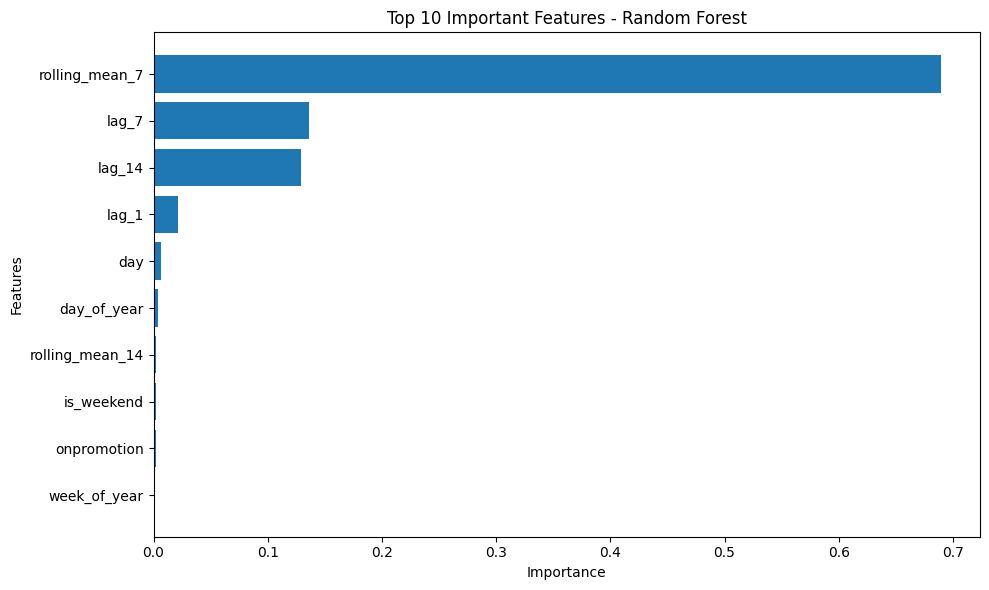

In [77]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(10)[::-1],
    feature_importance["Importance"].head(10)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [78]:
# compare actual and predicted sales
# Create comparison DataFrame

comparison = pd.DataFrame({
    "Actual Sales": y_val.values,
    "Predicted Sales": rf_predictions
})

# Display first 20 predictions
display(comparison.head(20))

,Actual Sales,Predicted Sales
0,2.0,3.811105
1,3.0,4.534686
2,7.0,3.770175
3,4.0,4.665563
4,10.0,4.559777
5,8.0,6.678656
6,0.0,5.096206
7,4.0,4.204348
8,10.0,4.807635
9,2.0,5.396860


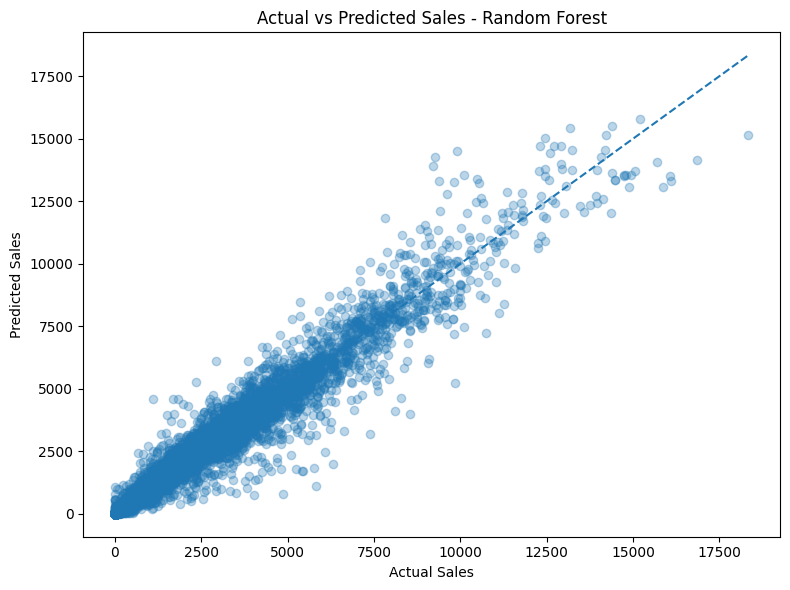

In [79]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    rf_predictions,
    alpha=0.3
)

# Perfect prediction reference line
max_value = max(y_val.max(), rf_predictions.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Random Forest")
plt.tight_layout()
plt.show()

In [81]:
import os
import joblib

# Create artifacts folder if it doesn't exist
os.makedirs("../artifacts", exist_ok=True)

# Save model and feature list
joblib.dump(
    {
        "model": rf_model,
        "features": feature_cols
    },
    "../artifacts/random_forest_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [82]:
import os
import joblib
import pandas as pd

# Create artifacts folder
os.makedirs("../artifacts", exist_ok=True)

# Store category mappings for future predictions
categorical_cols = [
    "store_nbr", "family", "day_of_week",
    "city", "state", "type", "cluster"
]

category_maps = {
    col: {
        value: code
        for code, value in enumerate(
            pd.Categorical(data[col]).categories
        )
    }
    for col in categorical_cols
}

# Save model, features and category mappings together
model_bundle = {
    "model": rf_model,
    "features": feature_cols,
    "category_maps": category_maps
}

joblib.dump(
    model_bundle,
    "../artifacts/random_forest_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [83]:
saved_model = joblib.load(
    "../artifacts/random_forest_model.pkl"
)

print("Model:", type(saved_model["model"]))
print("Number of features:", len(saved_model["features"]))
print("Saved category mappings:", list(saved_model["category_maps"].keys()))

Model: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
Number of features: 19
Saved category mappings: ['store_nbr', 'family', 'day_of_week', 'city', 'state', 'type', 'cluster']


In [84]:
test_df

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0
...,...,...,...,...,...
28507,3029395,2017-08-31,9,POULTRY,1
28508,3029396,2017-08-31,9,PREPARED FOODS,0
28509,3029397,2017-08-31,9,PRODUCE,1
28510,3029398,2017-08-31,9,SCHOOL AND OFFICE SUPPLIES,9


In [85]:
test_df["date"] = pd.to_datetime(test_df["date"])

print("Test dataset shape:", test_df.shape)

display(test_df.head())

Test dataset shape: (28512, 5)


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [86]:
print("Test start date:", test_df["date"].min())
print("Test end date:", test_df["date"].max())

print("Number of stores:", test_df["store_nbr"].nunique())

print("Number of product families:", test_df["family"].nunique())

Test start date: 2017-08-16 00:00:00
Test end date: 2017-08-31 00:00:00
Number of stores: 54
Number of product families: 33


In [ ]:
import numpy as np
import pandas as pd
import joblib

# Load saved model
model_bundle = joblib.load(
    "../artifacts/random_forest_model.pkl"
)

rf_model = model_bundle["model"]
feature_cols = model_bundle["features"]
category_maps = model_bundle["category_maps"]

# Store information lookup
store_info = stores_df.set_index("store_nbr").to_dict("index")

# Prepare historical sales for each store-family combination
history = {}

historical_data = train_df.sort_values("date")

for (store, family), group in historical_data.groupby(
    ["store_nbr", "family"]
):
    history[(store, family)] = group["sales"].tail(14).tolist()

# Sort future records
future_data = test_df.sort_values(
    ["date", "store_nbr", "family"]
).copy()

predictions = []

# Generate predictions one day at a time
for current_date, daily_data in future_data.groupby("date", sort=True):

    for _, row in daily_data.iterrows():

        store = row["store_nbr"]
        family = row["family"]

        previous_sales = history[(store, family)]
        store_details = store_info[store]

        day_name = current_date.day_name()

        # Create features
        features = {
            "store_nbr": category_maps["store_nbr"][store],
            "family": category_maps["family"][family],
            "onpromotion": row["onpromotion"],
            "day_of_week": category_maps["day_of_week"][day_name],
            "city": category_maps["city"][store_details["city"]],
            "state": category_maps["state"][store_details["state"]],
            "type": category_maps["type"][store_details["type"]],
            "cluster": category_maps["cluster"][store_details["cluster"]],
            "year": current_date.year,
            "month": current_date.month,
            "day": current_date.day,
            "day_of_year": current_date.dayofyear,
            "week_of_year": current_date.isocalendar().week,
            "is_weekend": int(current_date.dayofweek >= 5),
            "lag_1": previous_sales[-1],
            "lag_7": previous_sales[-7],
            "lag_14": previous_sales[-14],
            "rolling_mean_7": np.mean(previous_sales[-7:]),
            "rolling_mean_14": np.mean(previous_sales[-14:])
        }

        # Predict sales
        input_data = pd.DataFrame([features])[feature_cols]

        predicted_sales = rf_model.predict(input_data)[0]

        # Sales cannot be negative
        predicted_sales = max(0, predicted_sales)

        predictions.append(predicted_sales)

        # Add prediction to history for the next forecast day
        previous_sales.append(predicted_sales)

        history[(store, family)] = previous_sales[-14:]


# Attach predictions to test dataset
forecast_df = future_data.copy()
forecast_df["predicted_sales"] = predictions

print("Forecasting completed!")
print("Forecast shape:", forecast_df.shape)

display(forecast_df.head(10))